<center><h1> ESNGrad <h1><center>

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import torch 
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
from pathlib import Path

# Table of Contents
* [Intro](#Introduction)
* [Data](#Data)
* [Model Specifications](#Model-Specifications)
    * [Diffusion Process](#Diffusion-Process)
    * [Encoding Network](#ESN)
    * [Denoiser Network](#Denoiser-Network)
    * [Training Specification](#Specs)
    * [Finalizing a Time-Series Diffusion Model](#TSdiff)
* [Training](#Training)
* [Testing](#Testing)

# Introduction

We try a simple forecast of the RV as in the paper. 

In [3]:
runs_path = Path('runs')
runs_path.exists()

True

# Data

In the paper they use `2000` obs as training set and a bit more than `2000` as test set. They use both $RV_t$  $\ln(RV_t)$ as target variables. 

In [4]:
from rcdiff.data.rv import RVSP500

rvSP500 = RVSP500()
(dates_train, RV_train), (dates_test, RV_test) = rvSP500.get_realized_variance_data(len_train=2000, 
                                                                                    standardize=False)

# Model Specifications

Here we can customized the models. A time series diffusion model, in our context, is the combination of three components: 

* A **diffusion process** (e.g. DDPM, DDIM, SDE VE, SDE VP, SDE/ODE, etc.) defines the **forward** and the **reverse** process of the generative model. From the codebase: `rcdiff/diff/` contains different forward and reverse processes. 

* A **temporal encoder model** (e.g. RNNs, Transformers, ESN) that summarizes the temporal dependency of the time-series and acts as a conditioning in the estimation of the noise (i.e. conditional score). Here we only focus on ESNs. From the codebase: `rcdiff/models/encoders` contains the ESN module. 

* A **denoiser network** $\epsilon_{\theta}(x^{k}_{t},s_{t-1}, k)$ that estimates at each step $k$ of the process, the amount of corruption added by the diffusion process. Here we only focus on a simple MLP. From the codebase: `rcdiff/models/denoisers` contains the denoiser module. 


## Diffusion Process

First we need to define our diffusion process. We use the standard `DDPM`. 

In [5]:
from rcdiff.diff import DDPM, BaseScheduler
from rcdiff.models.config import build_diffusion, DiffusionConfig

K = 100

diffConfig = DiffusionConfig(num_timesteps = K, 
                beta_1 = 1e-4, 
                beta_K = 0.1,
                mode = "linear",
                s = 0.008,
                process = 'ddpm'
                )

## ESN

Second, we need to define the encoder network. We use the `ESN` module and sample the parameters: 

In [6]:
from rcdiff import ESN 
from rcdiff import RandomWeight, ParametersESN
from rcdiff.models.config import ESNConfig, build_esn, RandomWeightConfig

R = 25 
T, N = RV_train.shape

A = RandomWeightConfig(dist="normal", sparsity=0, norm_type="spectral_radius")
C = RandomWeightConfig(dist="uniform", sparsity=0, norm_type="l2")
zeta = RandomWeightConfig(dist="uniform", sparsity=0, norm_type="euclidean")

esnConfig = ESNConfig(reservoir_size = 50, 
                A = A, 
                C = C,
                zeta = zeta,
                leak_rate = 0.3, 
                rho = 0.9, 
                gamma = 0.1,
                omega = 0)

## Denoiser Network

Then we need to define the denoiser network. Here we use the `SimpleMLP` network

In [7]:
from rcdiff.models.denoisers import SimpleMLP 
from rcdiff.models.config import DenoiserConfig

denoiserConfig = DenoiserConfig("simple_mlp", {"dim_hids": [32, 32], "time_dim": 132})

## Specs

Here we then define the training characteristics of the network: 

In [8]:
from rcdiff.models.config import TrainConfig

train_spec = TrainConfig(t0 = 100,                            
    batch_size = 256,
    lr = 1e-3,
    max_iters = 1000,
    val_fraction = 0.25, 
    eval_every = 1,
    patience = 100,  
    ema_decay = 0.99,  
    grad_clip = 1.0,
    seed = 1234,
    device = "cpu")

## TSdiff

In [ ]:
from rcdiff.models.config import ExperimentConfig, build_diffusion, build_denoiser, build_esn
from rcdiff.models import ESNGrad

cfg = ExperimentConfig(name="rv_simple", 
                       in_dim=1,
                       n_covariates = 0,
                       esn = esnConfig,
                       denoiser = denoiserConfig,
                       diffusion = diffConfig,
                       train = train_spec
                       )

run_n = 1
path = runs_path / 'rv/esn_grad_ex1.yaml'
if path.exists(): 
    raise ValueError('yaml file already existent!')
cfg.to_yaml(path)

## Load directly from yaml file

In [17]:
cfg = ExperimentConfig.from_yaml(path)
model = ESNGrad(diff=build_diffusion(cfg), esn=build_esn(cfg),
                denoiser=build_denoiser(cfg), spec=cfg.train)

# Training

In [18]:
loss, time = model.fit(x = RV_train, c = None)

Early stopping at iteration 335 | best val loss 0.1130


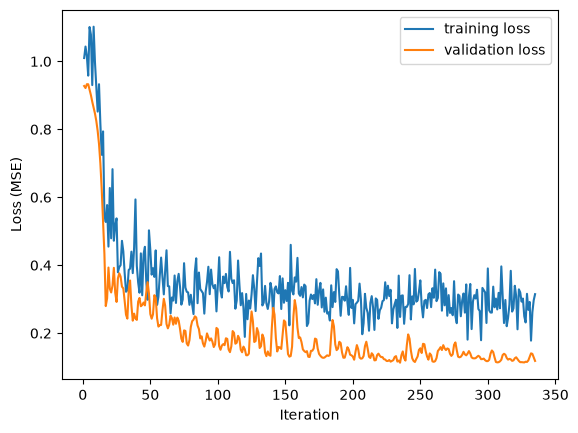

In [19]:
plt.plot(loss['iter'], loss['train'], label = 'training loss')
plt.plot(loss['iter'], loss['val'], label = 'validation loss')
plt.ylabel('Loss (MSE)')
plt.xlabel('Iteration')
plt.legend()
plt.show()

# Test

Using the `conditional_distribution` method you can sample from $p(x_t|s_{t-1})$ 

In [21]:
x_hat, process_history = model.conditional_distribution(x = RV_train, c = None, n_samples=1000)

In [22]:
print(RV_test[0])
print(x_hat.mean(dim = 0))

tensor([0.6725])
tensor([0.4629])


using the `one_step_ahead_forecast` you perform a one-step ahead forecast in a recursive way

In [23]:
obs = len(RV_test) # 1000 
test = RV_test[:obs]

forecast = model.one_step_ahead_forecast(x_train = RV_train, 
                                           x_test = test,
                                           n_samples = 50)

100%|██████████| 2096/2096 [04:21<00:00,  8.01it/s]


In [25]:
torch.save(forecast, f"runs/rv/forecast_ex{run_n}.pt")

forecast = torch.load(f"runs/rv/forecast_ex{run_n}.pt", weights_only=True)

In [26]:
import torch.nn.functional as F 

F_m = forecast.mean(dim = 1)

F.mse_loss(F_m, test) # should be around 3.6 to be good

tensor(5.6031)

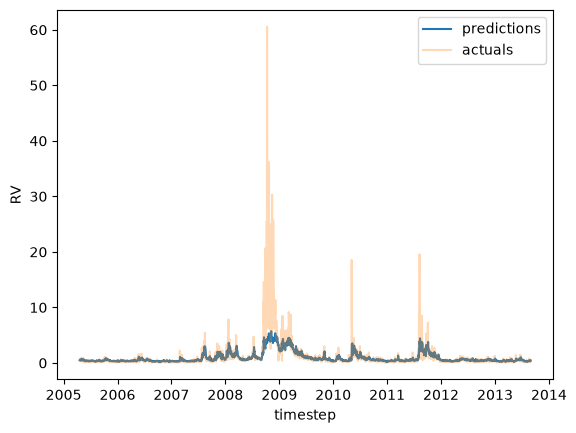

In [27]:
import matplotlib.pyplot as plt 

loss = pd.DataFrame(loss)
plt.plot(dates_test,F_m.detach().numpy(), label = 'predictions')
plt.plot(dates_test, RV_test.detach().numpy(), label = 'actuals', alpha = 0.3)
plt.ylabel('RV')
plt.xlabel('timestep')
plt.legend()
plt.show()